# Insurance Cost — Exploratory Data Analysis (EDA)
**Goal:** understand which factors affect `expenses` before modelling.

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Download latest version
path = kagglehub.dataset_download("noordeen/insurance-premium-prediction")

print("Path to dataset files:", path)
df = pd.read_csv(path + "/insurance.csv")
df.head()

Using Colab cache for faster access to the 'insurance-premium-prediction' dataset.
Path to dataset files: /kaggle/input/insurance-premium-prediction


,age,sex,bmi,children,smoker,region,expenses
0,19,female,27.9,0,yes,southwest,16884.92
1,18,male,33.8,1,no,southeast,1725.55
2,28,male,33.0,3,no,southeast,4449.46
3,33,male,22.7,0,no,northwest,21984.47
4,32,male,28.9,0,no,northwest,3866.86


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   expenses  1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [ ]:
df.describe()

,age,bmi,children,expenses
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.665471,1.094918,13270.422414
std,14.049960,6.098382,1.205493,12110.011240
min,18.000000,16.000000,0.000000,1121.870000
25%,27.000000,26.300000,0.000000,4740.287500
50%,39.000000,30.400000,1.000000,9382.030000
75%,51.000000,34.700000,2.000000,16639.915000
max,64.000000,53.100000,5.000000,63770.430000


In [ ]:
df.shape

(1338, 7)

## Data cleaning

In [ ]:
print(df.isna().sum().sum(), "missing values")
print(df.duplicated().sum(), "duplicated row")
df = df.drop_duplicates()
df.shape

0 missing values
1 duplicated row


(1337, 7)

No missing values. One duplicate row was removed (1,337 rows remain).

## Target and outliers

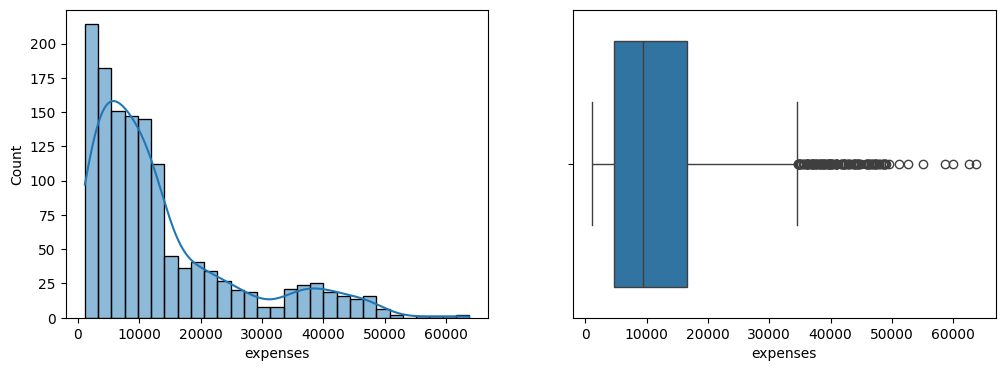

Outliers: 139
Smokers among outliers: 0.98


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df['expenses'], kde=True, ax=ax[0])
sns.boxplot(x=df['expenses'], ax=ax[1])
plt.show()

q1, q3 = df['expenses'].quantile([0.25, 0.75])
outliers = df[df['expenses'] > q3 + 1.5 * (q3 - q1)]
print("Outliers:", len(outliers))
print("Smokers among outliers:", (outliers['smoker'] == 'yes').mean().round(2))

`expenses` is right-skewed and the boxplot flags 139 high values as outliers. **We keep them**, because they are not errors: 98% of them are smokers (see H2), and age and BMI are within logical ranges (age 18–64, BMI 16–53). Removing them would delete exactly the high-cost customers the model needs to learn.

# H1

People with children pay more than people without.

children
0    12384.695515
1    12731.171821
2    15073.564000
3    15355.318535
4    13850.656800
5     8786.035556
Name: expenses, dtype: float64


<Axes: xlabel='children', ylabel='expenses'>

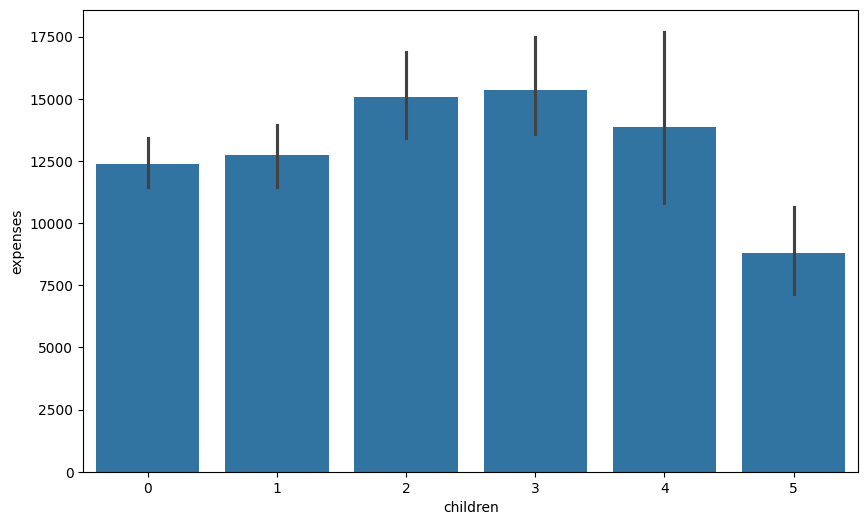

In [ ]:
print(df.groupby('children')['expenses'].mean())
plt.figure(figsize=(10, 6))
sns.barplot(x='children', y='expenses', data=df)

# A1
Not confirmed. Expenses rise slightly up to 3 children, then drop for 4–5 children, but those groups are very small (25 and 18 people). The effect is weak and inconsistent.

# H2

Smokers pay more than non-smokers.

smoker
no      8440.660461
yes    32050.231971
Name: expenses, dtype: float64


<Axes: xlabel='smoker', ylabel='expenses'>

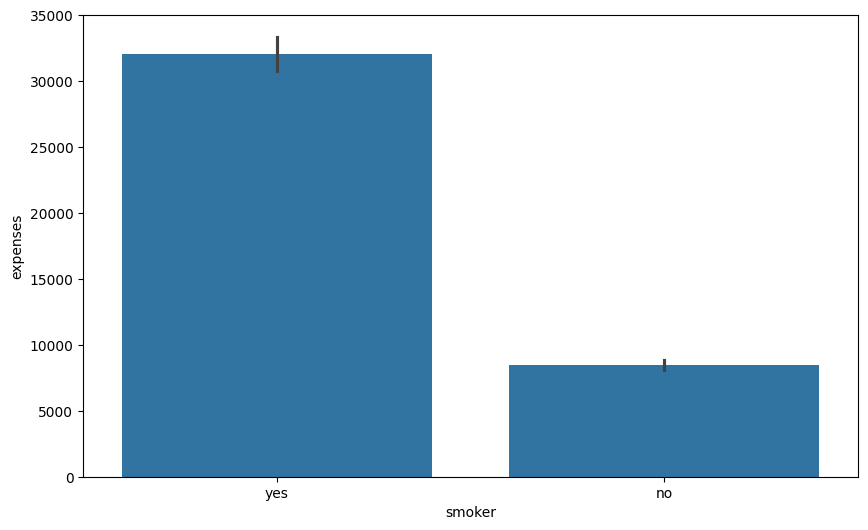

In [ ]:
print(df.groupby('smoker')['expenses'].mean())
plt.figure(figsize=(10, 6))
sns.barplot(x='smoker', y='expenses', data=df)

# A2
Confirmed. Smokers pay about 32k on average versus 8.4k for non-smokers (almost 4×).

# H3

Higher BMI means higher expenses.

obese
False    10713.666926
True     15572.042210
Name: expenses, dtype: float64

smoker  obese
no      False     7977.029602
        True      8855.531569
yes     False    21363.216822
        True     41557.990276
Name: expenses, dtype: float64


<Axes: xlabel='bmi', ylabel='expenses'>

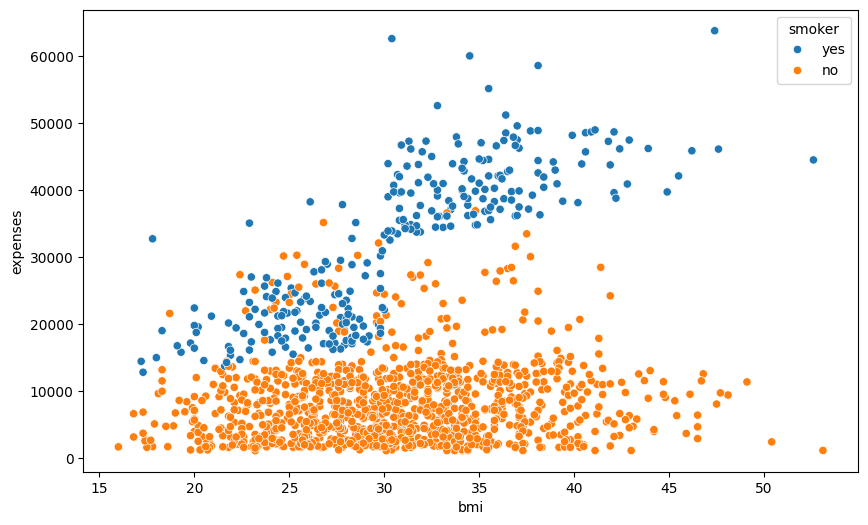

In [ ]:
df['obese'] = df['bmi'] >= 30
print(df.groupby('obese')['expenses'].mean())
print()
print(df.groupby(['smoker', 'obese'])['expenses'].mean())
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='bmi', y='expenses', hue='smoker')

# A3
Confirmed, but only for smokers. Obese people (BMI ≥ 30) pay more on average (15.6k vs 10.7k), but the scatter plot shows the high-cost cluster above BMI 30 is made of smokers. For non-smokers BMI barely matters (8.0k vs 8.9k), while obese smokers pay about 41.6k versus 21.4k for non-obese smokers.

# H4

Older people pay more. *(added)*

age_group
18-29     9200.619351
30-39    11738.784241
40-49    14399.203656
50-64    17902.552234
Name: expenses, dtype: float64


/tmp/ipykernel_631/2463654262.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby('age_group')['expenses'].mean())


<Axes: xlabel='age', ylabel='expenses'>

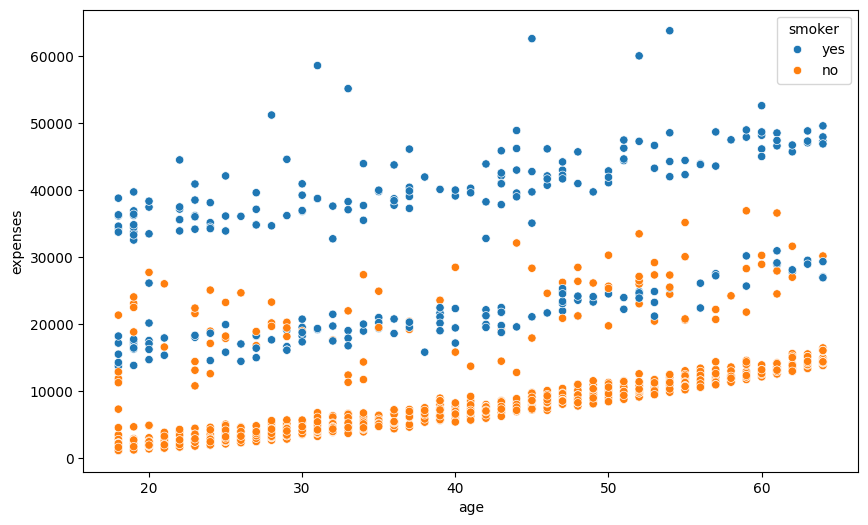

In [ ]:
df['age_group'] = pd.cut(df['age'], [17, 29, 39, 49, 64], labels=['18-29', '30-39', '40-49', '50-64'])
print(df.groupby('age_group')['expenses'].mean())
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='age', y='expenses', hue='smoker')

# A4
Confirmed. Average expenses rise steadily with age (about 9.2k to 17.9k), for both smokers and non-smokers.

## Correlation

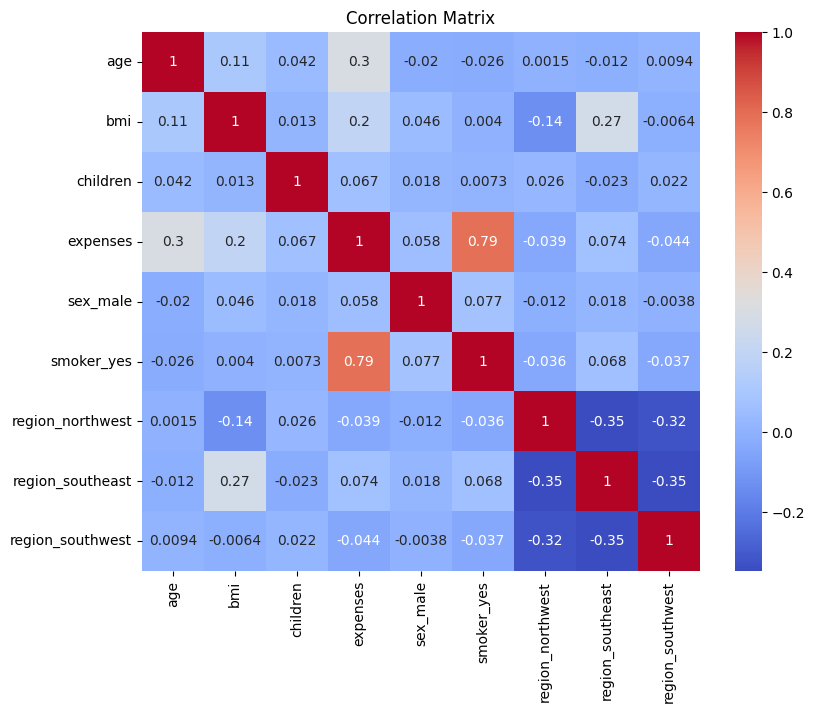

In [ ]:
df_corr = pd.get_dummies(df[['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'expenses']], drop_first=True)

plt.figure(figsize=(9, 7))
sns.heatmap(df_corr.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

The heatmap now includes the categorical columns (`smoker`, `sex`, `region`), which the numeric-only version left out. Correlation with `expenses`: `smoker` 0.79, `age` 0.30, `bmi` 0.20, `children` 0.07, `sex` 0.06, regions about 0. So `smoker` is the strongest factor but not the only positive one; `age` and `bmi` are positive too, and `sex` and `region` have almost no effect.

# EDA Summary
| | Result |
|---|---|
| Data quality | Clean; 1 duplicate removed |
| Outliers | Kept: high expenses are real (mostly smokers); age and BMI are logical |
| H1 Children | Weak, inconsistent effect |
| H2 Smoker | Strongest factor: about 4× higher expenses |
| H3 BMI | Raises expenses only for smokers |
| H4 Age | Expenses rise steadily with age |
| Sex, region | Almost no effect |

**Ranking of factors:** smoker ≫ age > bmi > children > sex, region.

#Model

## How does SVR work?

### 1. The ε-tube
SVR draws a line (or curve) through the data with a **tube** of width **±ε** around it.

- Points **inside** the tube → no penalty
- Points **outside** the tube → penalized

### 2. Support vectors
The points on or outside the tube are called **support vectors**.
Only these points decide where the line goes; points inside the tube don't affect the model.

### 3. The kernel trick
A straight line can't fit curved data.
A **kernel** lets SVR fit curves. The most common is the **RBF kernel**, which can follow complex, non-linear patterns.


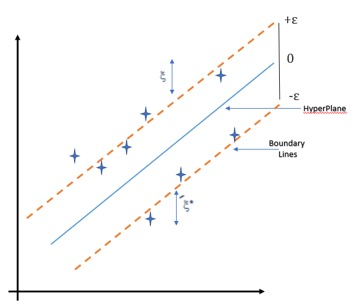

## Key hyperparameters

| Parameter | What it controls | Too low | Too high |
|---|---|---|---|
| **C** | Penalty for points outside the tube | Too simple (underfits) | Chases every point (overfits) |
| **ε (epsilon)** | Width of the tube | Too strict | Ignores real patterns |
| **γ (gamma)** | How curvy the line can be | Too smooth | Too wiggly (overfits) |

In [ ]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [ ]:
df = pd.get_dummies(df, columns=["sex", "smoker", "region"], drop_first=True)

X = df.drop(columns=["expenses", "age_group"])
y = df["expenses"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

### Feature scaling
SVR is based on distances, so features with larger ranges (like age, 18–64) would dominate smaller ones (like children, 0–5). `StandardScaler` puts all features on the same scale (mean 0, standard deviation 1).

The scaler is fitted on the training data only, to avoid leaking information from the test set.

In [ ]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
def evaluate(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    print(name)
    print("MAE: ", mean_absolute_error(y_true, y_pred))
    print("MSE: ", mse)
    print("RMSE:", np.sqrt(mse))
    print("R²:  ", r2_score(y_true, y_pred))
    print()

### Model 1: Default SVR
We first train SVR with default settings (C=1, epsilon=0.1, RBF kernel) as a baseline.

In [ ]:
svr = SVR()
svr.fit(X_train, y_train)
evaluate("SVR (default)", y_test, svr.predict(X_test))

SVR (default)
MAE:  9268.128563541759
MSE:  207865943.49007377
RMSE: 14417.556779498867
R²:   -0.13120587083763957



**Result:** R² = −0.13, worse than just predicting the average.
The target (expenses) is in the thousands, which is too large for the default settings.

### Model 2: SVR with scaled target
`TransformedTargetRegressor` scales `expenses` before training and automatically converts predictions back to dollars.

In [ ]:
svr_scaled = TransformedTargetRegressor(regressor=SVR(), transformer=StandardScaler())
svr_scaled.fit(X_train, y_train)
evaluate("SVR (scaled target)", y_test, svr_scaled.predict(X_test))

SVR (scaled target)
MAE:  2180.012181628109
MSE:  19576584.54908979
RMSE: 4424.54342832001
R²:   0.893464282791773



**Result:** R² = 0.89, MAE = \$2,180.
Scaling the target fixed the model.

### Model 3: Tuned SVR
We use GridSearchCV to find the best C, epsilon and gamma.

In [ ]:
params = {
    "regressor__C": [1, 10, 100],
    "regressor__epsilon": [0.01, 0.1, 0.5],
    "regressor__gamma": ["scale", 0.01, 0.1]
}
grid = GridSearchCV(svr_scaled, params, cv=5, scoring="r2")
grid.fit(X_train, y_train)
print("Best params:", grid.best_params_)
evaluate("SVR (tuned)", y_test, grid.predict(X_test))

Best params: {'regressor__C': 100, 'regressor__epsilon': 0.1, 'regressor__gamma': 0.01}
SVR (tuned)
MAE:  2098.3146555157728
MSE:  16674772.075235523
RMSE: 4083.4754897312073
R²:   0.9092559379873274



**Result:** R² = 0.90, MAE = \$2,098.
Best settings: C=100, epsilon=0.1, gamma=0.01. Small improvement over Model 2.

### Bonus: comparison with Linear Regression
We compare SVR against Linear Regression to see whether SVR's non-linear kernel gives an advantage.

In [ ]:
lr = LinearRegression()
lr.fit(X_train, y_train)
evaluate("Linear Regression", y_test, lr.predict(X_test))

Linear Regression
MAE:  4287.569355466175
MSE:  35738497.03640722
RMSE: 5978.168368021029
R²:   0.8055112011918972



  **Result:** R² = 0.81, MAE = \$4,288.
  Tuned SVR is better (R² 0.91) because it can capture non-linear patterns, like smokers with high BMI.

| Model | MAE (USD) | RMSE (USD) | R² |
|---|---|---|---|
| Default SVR | 9,268 | 14,418 | −0.13 |
| SVR (scaled target) | 2,180 | 4,425 | 0.893 |
| **SVR (tuned)** | **2,098** | **4,083** | **0.909** |
| Linear Regression | 4,288 | 5,978 | 0.806 |